In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os
os.makedirs('dataset/processed', exist_ok=True)
warnings.filterwarnings('ignore')

In [4]:
df=pd.read_csv("airports.csv")
df.head()

,id,ident,type,name,latitude_deg,longitude_deg,elevation_ft,continent,iso_country,iso_region,municipality,scheduled_service,icao_code,iata_code,gps_code,local_code,home_link,wikipedia_link,keywords
0,6523,00A,heliport,Total RF Heliport,40.070985,-74.933689,11.0,NaN,US,US-PA,Bensalem,no,NaN,NaN,K00A,00A,https://www.penndot.pa.gov/TravelInPA/airports...,NaN,NaN
1,323361,00AA,small_airport,Aero B Ranch Airport,38.704022,-101.473911,3435.0,NaN,US,US-KS,Leoti,no,NaN,NaN,00AA,00AA,NaN,NaN,NaN
2,6524,00AK,small_airport,Lowell Field,59.947733,-151.692524,450.0,NaN,US,US-AK,Anchor Point,no,NaN,NaN,00AK,00AK,NaN,NaN,NaN
3,6525,00AL,small_airport,Epps Airpark,34.864799,-86.770302,820.0,NaN,US,US-AL,Harvest,no,NaN,NaN,00AL,00AL,NaN,NaN,NaN
4,506791,00AN,small_airport,Katmai Lodge Airport,59.093287,-156.456699,80.0,NaN,US,US-AK,King Salmon,no,NaN,NaN,00AN,00AN,NaN,NaN,NaN


In [7]:
df.shape
df.info()

(86363, 19)

In [9]:
missing_values = df.isnull().sum()
missing_df=pd.DataFrame({"column":missing_values.index,
                         "missing values":missing_values.values,
                         "missing percentage":(missing_values.values /len(df)*100).round(2)})
missing_df=missing_df.sort_values(by="missing percentage",ascending=False)
display(missing_df)

,column,missing values,missing percentage
16,home_link,81584,94.47
13,iata_code,77310,89.52
12,icao_code,75679,87.63
17,wikipedia_link,69594,80.58
18,keywords,64443,74.62
15,local_code,50204,58.13
14,gps_code,41900,48.52
7,continent,39843,46.13
6,elevation_ft,14982,17.35
10,municipality,4777,5.53


In [12]:
df.duplicated().sum()


0

In [11]:
data_types = pd.DataFrame({
    'Column': df.columns,
    'Data Type': df.dtypes.astype(str).values,
    'Unique Values': df.nunique().values
})
display(data_types)

,Column,Data Type,Unique Values
0,id,int64,86363
1,ident,object,86363
2,type,object,7
3,name,object,81751
4,latitude_deg,float64,85367
5,longitude_deg,float64,85627
6,elevation_ft,float64,6484
7,continent,object,6
8,iso_country,object,246
9,iso_region,object,3020


In [13]:
invalid_latitude = (
    (df['latitude_deg'] < -90) |
    (df['latitude_deg'] > 90)
).sum()

invalid_longitude = (
    (df['longitude_deg'] < -180) |
    (df['longitude_deg'] > 180)
).sum()

print("Invalid Latitude Records:", invalid_latitude)
print("Invalid Longitude Records:", invalid_longitude)

print("\nMissing Latitude:", df['latitude_deg'].isnull().sum())
print("Missing Longitude:", df['longitude_deg'].isnull().sum())


Invalid Latitude Records: 0
Invalid Longitude Records: 0

Missing Latitude: 0
Missing Longitude: 0


In [14]:
df_clean = df.copy()
print("Original Dataset Shape:", df_clean.shape)
df_clean = df_clean.drop_duplicates()
df_clean = df_clean.drop_duplicates(subset=['id'], keep='first')
print("After Removing Duplicates:", df_clean.shape)
print("Duplicate Records Remaining:", df_clean.duplicated().sum())


Original Dataset Shape: (86363, 19)
After Removing Duplicates: (86363, 19)
Duplicate Records Remaining: 0


In [15]:
print("Missing Latitude:",
      df_clean['latitude_deg'].isnull().sum())
print("Missing Longitude:",
      df_clean['longitude_deg'].isnull().sum())
geo_df = df_clean.dropna(
    subset=['latitude_deg', 'longitude_deg']
).copy()


Missing Latitude: 0
Missing Longitude: 0


In [16]:
geo_df = geo_df[
    geo_df['latitude_deg'].between(-90, 90) &
    geo_df['longitude_deg'].between(-180, 180)
].copy()

print("Valid Coordinate Records:", len(geo_df))

print("\nLatitude Range:")
print(geo_df['latitude_deg'].min(),
      "to",
      geo_df['latitude_deg'].max())

print("\nLongitude Range:")
print(geo_df['longitude_deg'].min(),
      "to",
      geo_df['longitude_deg'].max())


Valid Coordinate Records: 86363

Latitude Range:
-90.0 to 83.091029

Longitude Range:
-179.876999 to 179.9757


In [21]:
df_clean.to_csv('dataset/processed/airports_cleaned.csv',index=False)
geo_df.to_csv('dataset/processed/airports_geospatial.csv',index=False)



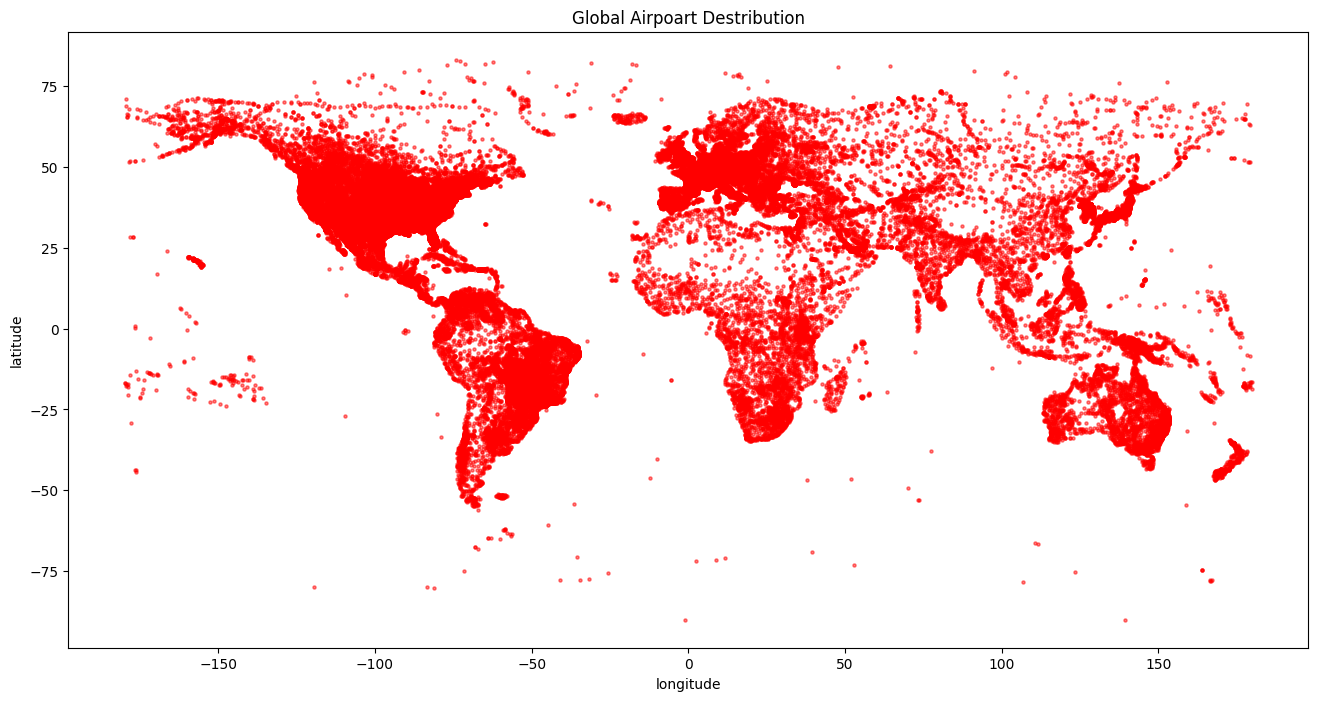

In [23]:
plt.figure(figsize=(16,8))
plt.scatter(geo_df["longitude_deg"],
            geo_df["latitude_deg"],
            s=5,alpha=0.5,color="red")
plt.title("Global Airpoart Destribution")
plt.xlabel("longitude")
plt.ylabel("latitude")
plt.show()

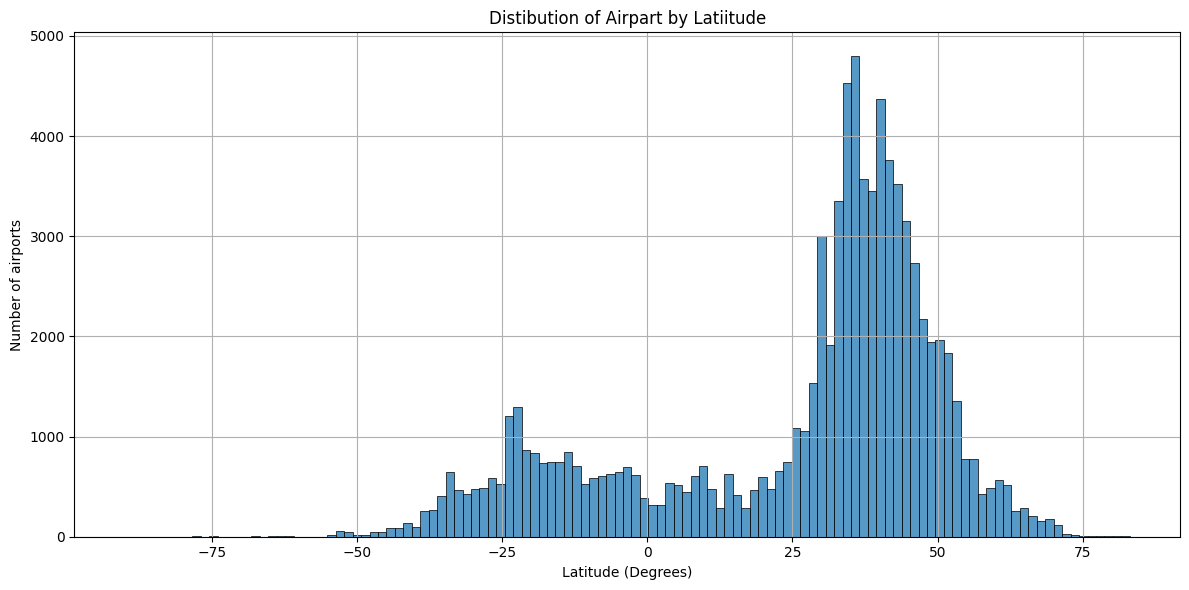

In [26]:
plt.figure(figsize=(12,6))
sns.histplot(data=geo_df,x="latitude_deg")
plt.title("Distibution of Airpart by Latiitude")
plt.xlabel("Latitude (Degrees)")
plt.ylabel("Number of airports")
plt.grid()
plt.tight_layout()
plt.show()

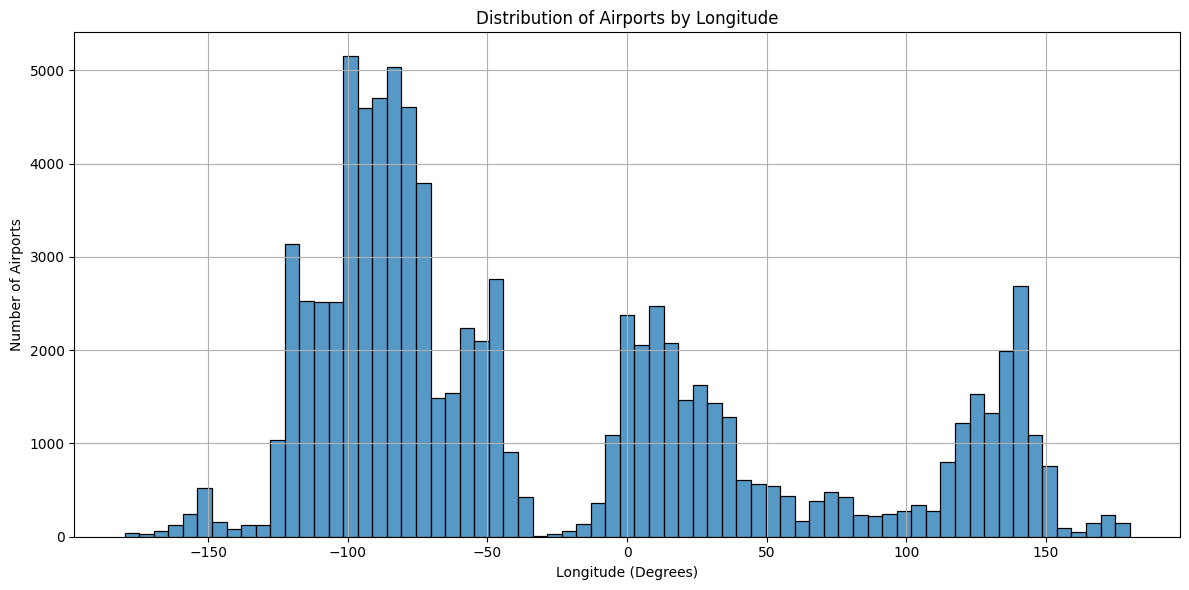

In [28]:
plt.figure(figsize=(12, 6))
sns.histplot(data=geo_df,x='longitude_deg',)
plt.title('Distribution of Airports by Longitude')
plt.xlabel('Longitude (Degrees)')
plt.ylabel('Number of Airports')
plt.grid()
plt.tight_layout()
plt.show()


Hemisphere
Northern Hemisphere    68497
Southern Hemisphere    17866
Name: count, dtype: int64

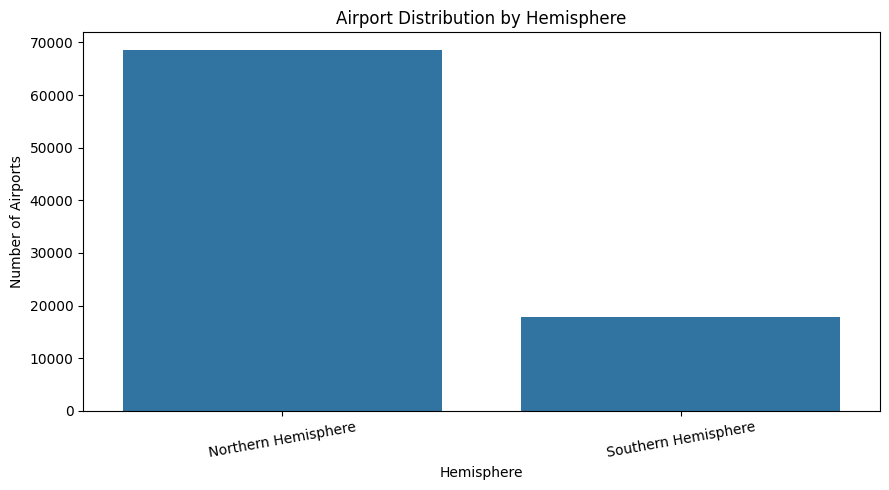

In [29]:
geo_df['Hemisphere'] = np.where(geo_df['latitude_deg'] >= 0,'Northern Hemisphere','Southern Hemisphere')
hemisphere_counts = geo_df['Hemisphere'].value_counts()
display(hemisphere_counts)
plt.figure(figsize=(9, 5))
sns.barplot(x=hemisphere_counts.index,y=hemisphere_counts.values)
plt.title('Airport Distribution by Hemisphere')
plt.xlabel('Hemisphere')
plt.ylabel('Number of Airports')
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


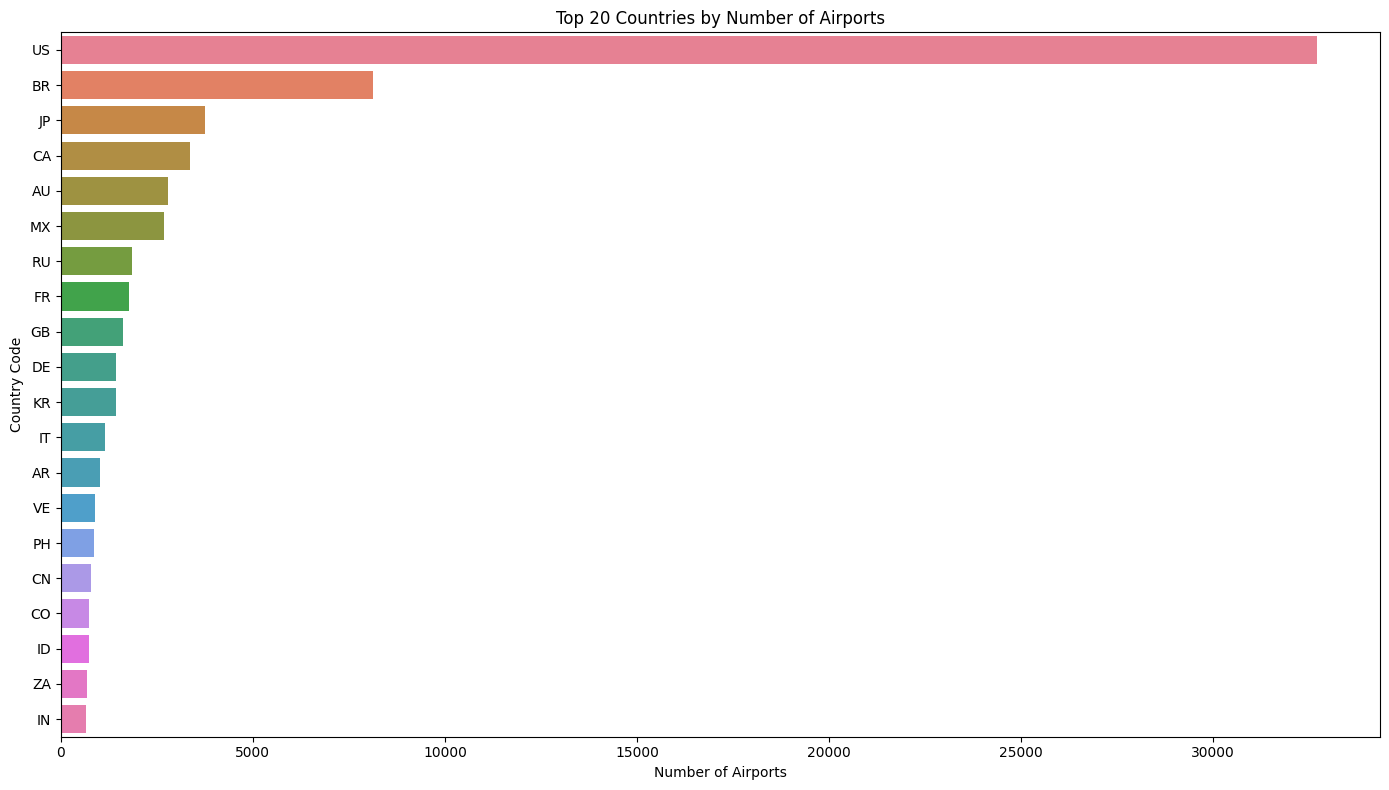

,Airport Count
iso_country,
US,32709
BR,8128
JP,3748
CA,3369
AU,2795
MX,2696
RU,1845
FR,1789
GB,1612


In [30]:

# Step 17: Top 20 Countries by Airport Count

country_counts = (geo_df['iso_country'].value_counts().head(20))
plt.figure(figsize=(14, 8))
sns.barplot(x=country_counts.values,y=country_counts.index,hue=country_counts.index)
plt.title('Top 20 Countries by Number of Airports')
plt.xlabel('Number of Airports')
plt.ylabel('Country Code')
plt.tight_layout()
plt.show()
display(country_counts.to_frame('Airport Count'))


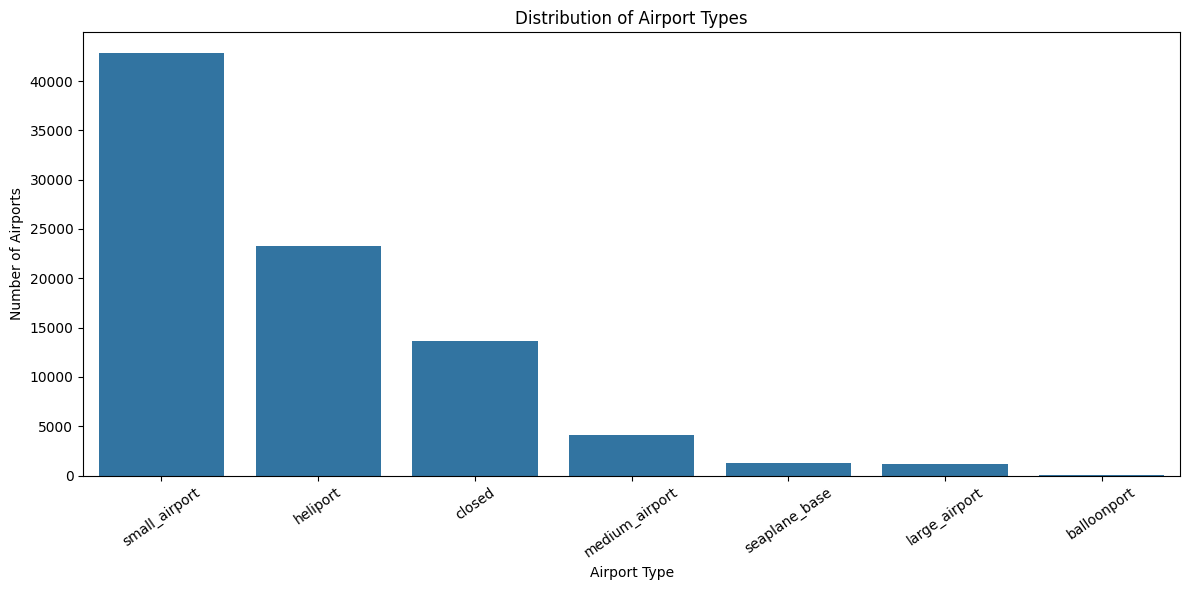

,Count
type,
small_airport,42797
heliport,23285
closed,13663
medium_airport,4107
seaplane_base,1274
large_airport,1175
balloonport,62


In [31]:

airport_types = geo_df['type'].value_counts()
plt.figure(figsize=(12, 6))
sns.barplot(x=airport_types.index,y=airport_types.values)
plt.title('Distribution of Airport Types',)
plt.xlabel('Airport Type')
plt.ylabel('Number of Airports')
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()
display(airport_types.to_frame('Count'))


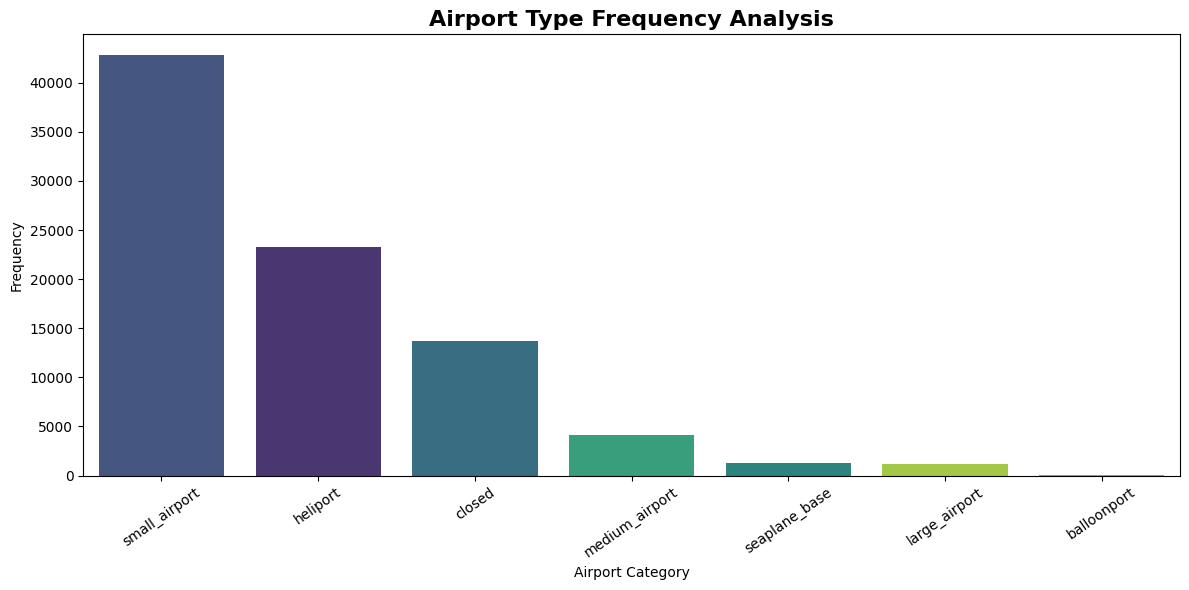

In [32]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=geo_df,
    x='type',
    order=geo_df['type'].value_counts().index,
    hue='type',
    palette='viridis',
    legend=False
)

plt.title('Airport Type Frequency Analysis',
          fontsize=16, fontweight='bold')

plt.xlabel('Airport Category')
plt.ylabel('Frequency')

plt.xticks(rotation=35)
plt.tight_layout()
plt.show()


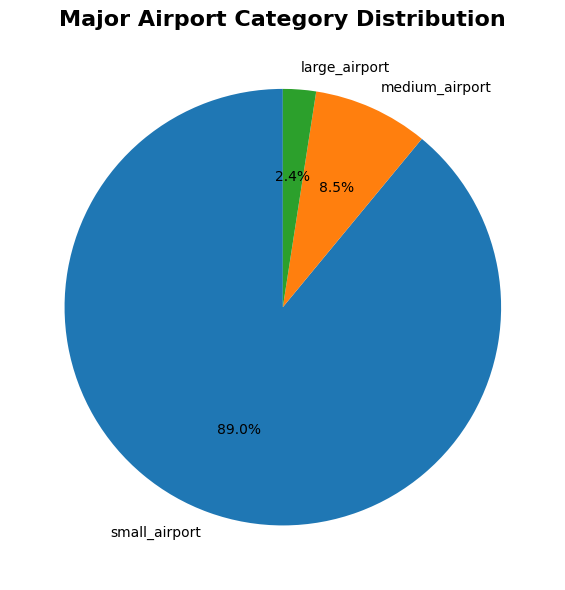

,Airport Count
type,
small_airport,42797
medium_airport,4107
large_airport,1175


In [33]:

# Step 20: Major Airport Categories Analysis

major_airports = geo_df[
    geo_df['type'].isin([
        'large_airport',
        'medium_airport',
        'small_airport'
    ])
].copy()

major_counts = major_airports['type'].value_counts()

plt.figure(figsize=(10, 6))

plt.pie(
    major_counts.values,
    labels=major_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Major Airport Category Distribution',
          fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()

display(major_counts.to_frame('Airport Count'))


In [34]:
import plotly.express as px

# Sample records for faster interactive visualization
map_df = geo_df.sample(
    n=min(5000, len(geo_df)),
    random_state=42
)

fig = px.scatter_geo(
    map_df,
    lat='latitude_deg',
    lon='longitude_deg',
    hover_name='name',
    hover_data=['type', 'iso_country'],
    title='Interactive Global Airport Distribution',
    projection='natural earth',
    color='type',
    opacity=0.6
)

fig.update_layout(
    height=700,
    template='plotly_white'
)

fig.show()


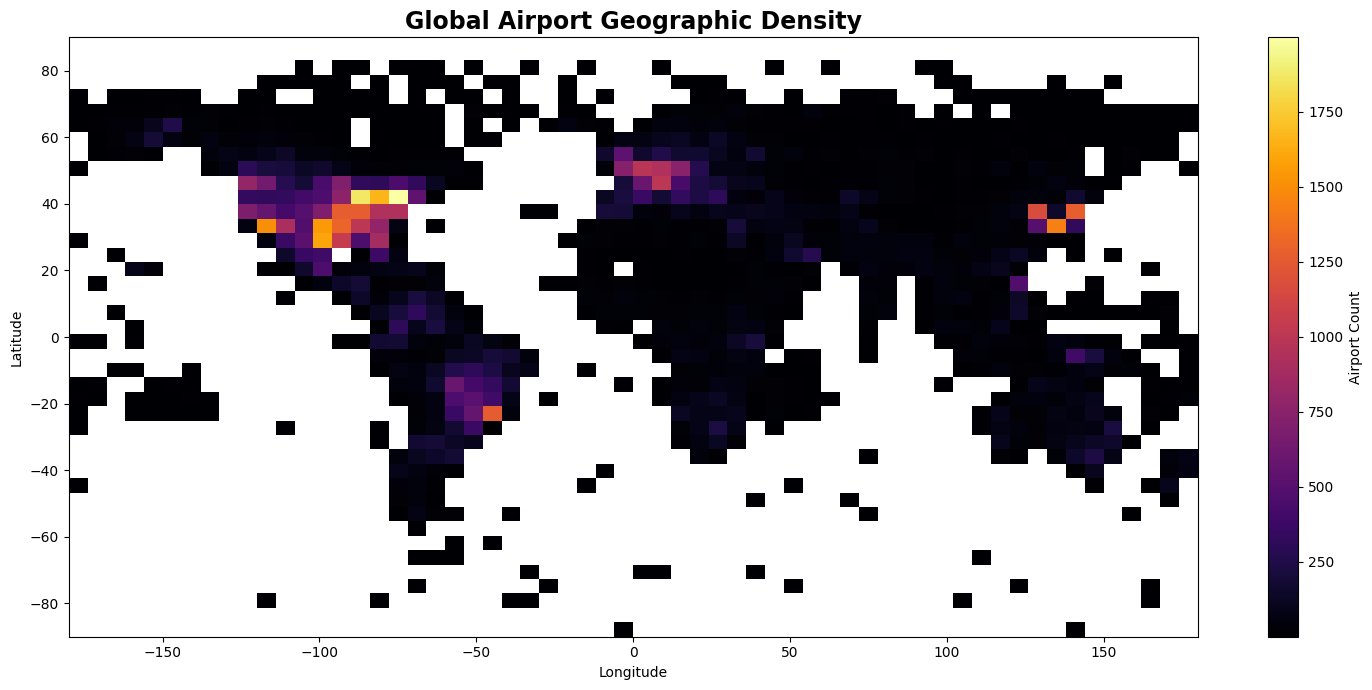

In [35]:

# Step 22: Geographic Density Analysis

plt.figure(figsize=(15, 7))

plt.hist2d(
    geo_df['longitude_deg'],
    geo_df['latitude_deg'],
    bins=[60, 40],
    cmap='inferno',
    cmin=1
)

plt.colorbar(label='Airport Count')

plt.title(
    'Global Airport Geographic Density',
    fontsize=17,
    fontweight='bold'
)

plt.xlabel('Longitude')
plt.ylabel('Latitude')

plt.xlim(-180, 180)
plt.ylim(-90, 90)

plt.tight_layout()
plt.show()


In [36]:

# Step 23: Geographic Clustering using DBSCAN

from sklearn.cluster import DBSCAN

from sklearn.preprocessing import StandardScaler

# Extract geographic coordinates
coordinates = geo_df[
    ['latitude_deg', 'longitude_deg']
].dropna().copy()

# Convert degrees to radians
coords_rad = np.radians(coordinates)

# DBSCAN using Haversine distance
earth_radius_km = 6371.0

dbscan = DBSCAN(
    eps=200 / earth_radius_km,
    min_samples=10,
    metric='haversine',
    algorithm='ball_tree'
)

cluster_labels = dbscan.fit_predict(coords_rad)

coordinates['Cluster'] = cluster_labels

print("Total Clusters:",
      len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0))

print("Noise Points:",
      (cluster_labels == -1).sum())

print("\nCluster Distribution:")
display(coordinates['Cluster'].value_counts().head(15))


Total Clusters: 57
Noise Points: 1104

Cluster Distribution:


Cluster
 0     51997
 4     22922
 3      3807
 5      3459
-1      1104
 12     1048
 42      331
 34      181
 45      159
 1       124
 6        96
 11       95
 19       86
 47       56
 20       42
Name: count, dtype: int64

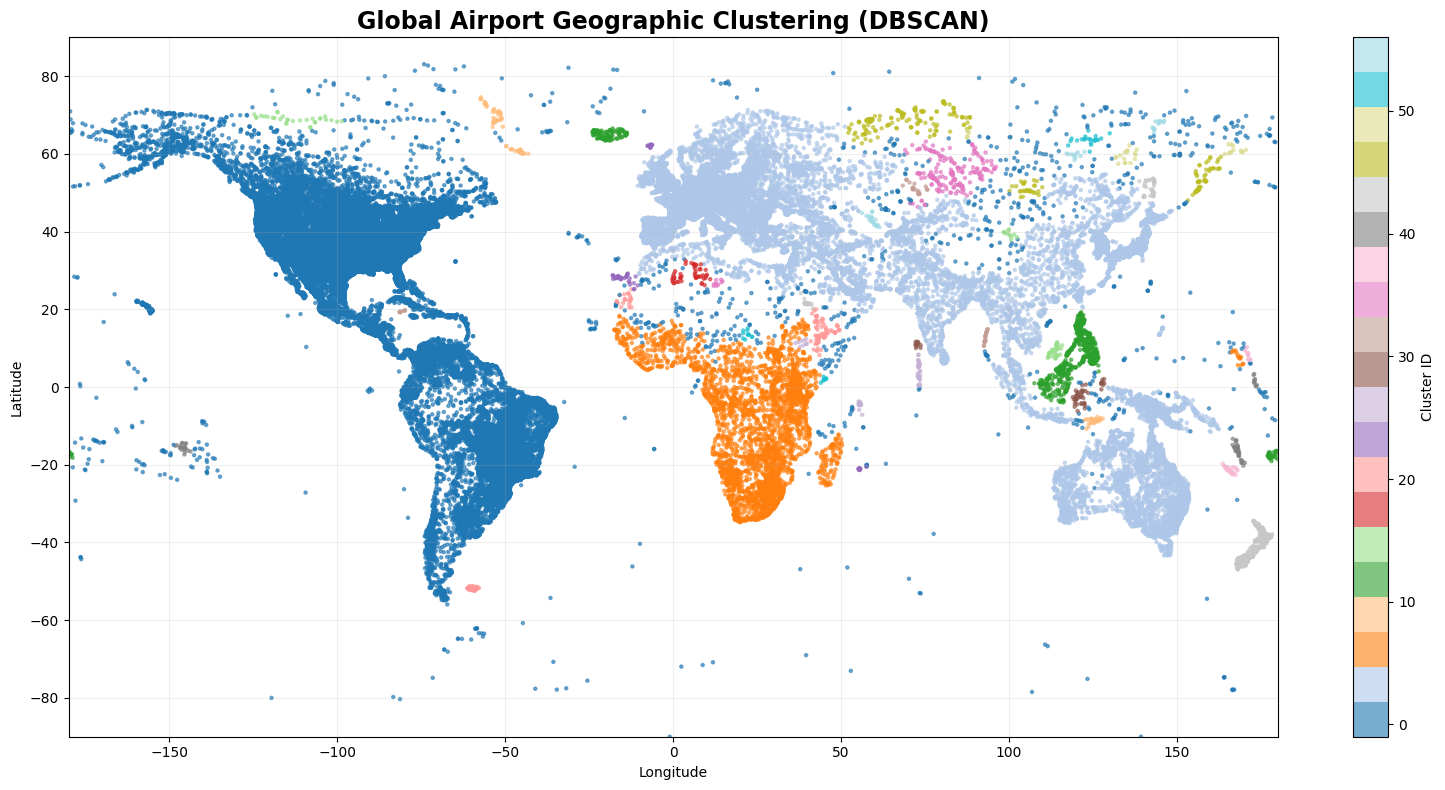

In [37]:

# Step 24: Visualize Airport Clusters

plt.figure(figsize=(16, 8))

scatter = plt.scatter(
    coordinates['longitude_deg'],
    coordinates['latitude_deg'],
    c=coordinates['Cluster'],
    cmap='tab20',
    s=5,
    alpha=0.6
)

plt.colorbar(scatter, label='Cluster ID')

plt.title(
    'Global Airport Geographic Clustering (DBSCAN)',
    fontsize=17,
    fontweight='bold'
)

plt.xlabel('Longitude')
plt.ylabel('Latitude')

plt.xlim(-180, 180)
plt.ylim(-90, 90)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [38]:

# Step 25: Statistical Insights

print("GLOBAL AVIATION STATISTICAL REPORT")
print("=" * 45)

print("Total Airports:", len(geo_df))

print("Countries Represented:",
      geo_df['iso_country'].nunique())

print("Airport Types:",
      geo_df['type'].nunique())

print("\nLATITUDE STATISTICS")
print(geo_df['latitude_deg'].describe())

print("\nLONGITUDE STATISTICS")
print(geo_df['longitude_deg'].describe())

print("\nTOP 5 COUNTRIES")
display(
    geo_df['iso_country']
    .value_counts()
    .head(5)
)

print("\nTOP AIRPORT TYPES")
display(
    geo_df['type']
    .value_counts()
    .head(5)
)


GLOBAL AVIATION STATISTICAL REPORT
Total Airports: 86363
Countries Represented: 246
Airport Types: 7

LATITUDE STATISTICS
count    86363.000000
mean        25.767546
std         26.276996
min        -90.000000
25%         10.738760
50%         35.157902
75%         43.128399
max         83.091029
Name: latitude_deg, dtype: float64

LONGITUDE STATISTICS
count    86363.000000
mean       -27.323930
std         85.100652
min       -179.876999
25%        -92.685194
50%        -63.067467
75%         23.693576
max        179.975700
Name: longitude_deg, dtype: float64

TOP 5 COUNTRIES


iso_country
US    32709
BR     8128
JP     3748
CA     3369
AU     2795
Name: count, dtype: int64


TOP AIRPORT TYPES


type
small_airport     42797
heliport          23285
closed            13663
medium_airport     4107
seaplane_base      1274
Name: count, dtype: int64

In [39]:
pip install streamlit plotly

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
